In [ ]:
!pip install -q xgboost scikit-survival

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 142.4/142.4 kB 2.2 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.0/4.0 MB 29.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 79.5 MB/s eta 0:00:00


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

from xgboost import XGBClassifier

from sksurv.ensemble import RandomSurvivalForest
from sksurv.util import Surv
from sksurv.metrics import concordance_index_censored

pd.set_option("display.max_columns", None)

In [ ]:
df = pd.read_csv("dataset telkom.csv", sep=";")

# Rapikan nama kolom dan spasi pada data teks
df.columns = df.columns.str.strip()

for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].str.strip()

print("Ukuran dataset:", df.shape)
display(df.head())

print("\nInformasi kolom:")
df.info()

Ukuran dataset: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes



Informasi kolom:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 n

In [ ]:
#Tenure dan Churn  disimpan dulu
df = df.dropna(subset=["Churn", "tenure"]).copy()

df["Churn"] = df["Churn"].astype(str).str.strip()
df["tenure"] = pd.to_numeric(df["tenure"], errors="coerce")

df = df.dropna(subset=["tenure"])
df = df[df["Churn"].isin(["Yes", "No"])].copy()

# Target klasifikasi: Yes = 1, No = 0
y = (df["Churn"] == "Yes").astype(int)

# Split sebelum proses encoding dan imputasi
train_df, test_df = train_test_split(
    df,
    test_size=0.20,
    random_state=42,
    stratify=y
)

y_train = (train_df["Churn"] == "Yes").astype(int)
y_test = (test_df["Churn"] == "Yes").astype(int)

print("Jumlah data latih:", len(train_df))
print("Jumlah data uji:", len(test_df))

print("\nProporsi churn pada data latih:")
print(y_train.value_counts(normalize=True))

print("\nProporsi churn pada data uji:")
print(y_test.value_counts(normalize=True))

Jumlah data latih: 5634
Jumlah data uji: 1409

Proporsi churn pada data latih:
Churn
0    0.734647
1    0.265353
Name: proportion, dtype: float64

Proporsi churn pada data uji:
Churn
0    0.734564
1    0.265436
Name: proportion, dtype: float64


# Cleaning

In [ ]:
df_clean = df.copy()

# Rapikan spasi pada data kategorikal
for col in df_clean.select_dtypes(include="object").columns:
    df_clean[col] = df_clean[col].str.strip()

# Ubah TotalCharges menjadi numerik
if "TotalCharges" in df_clean.columns:
    df_clean["TotalCharges"] = pd.to_numeric(
        df_clean["TotalCharges"],
        errors="coerce"
    )

print("SETELAH PEMBERSIHAN FORMAT")
print("\nUkuran data:", df_clean.shape)

print("\nTipe data setelah perubahan:")
print(df_clean.dtypes)

SETELAH PEMBERSIHAN FORMAT

Ukuran data: (7043, 21)

Tipe data setelah perubahan:
customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges        float64
Churn                object
dtype: object


In [ ]:
missing_summary = pd.DataFrame({
    "Jumlah Missing": df_clean.isna().sum(),
    "Persentase Missing (%)": (
        df_clean.isna().mean() * 100
    ).round(2)
})

print("MISSING VALUE")
display(
    missing_summary[
        missing_summary["Jumlah Missing"] > 0
    ].sort_values("Jumlah Missing", ascending=False)
)

print("Total seluruh missing value:",
      df_clean.isna().sum().sum())

MISSING VALUE


,Jumlah Missing,Persentase Missing (%)
TotalCharges,11,0.16


Total seluruh missing value: 11


In [ ]:
print("Jumlah seluruh baris:", len(df_clean))
print("Jumlah baris duplikat:", df_clean.duplicated().sum())

if "customerID" in df_clean.columns:
    print(
        "Jumlah customerID duplikat:",
        df_clean["customerID"].duplicated().sum()
    )

Jumlah seluruh baris: 7043
Jumlah baris duplikat: 0
Jumlah customerID duplikat: 0


In [ ]:
print("DISTRIBUSI TARGET CHURN")

display(
    df_clean["Churn"]
    .value_counts(dropna=False)
    .rename_axis("Status Churn")
    .to_frame("Jumlah")
)

display(
    (df_clean["Churn"].value_counts(normalize=True) * 100)
    .round(2)
    .rename("Persentase (%)")
    .to_frame()
)

DISTRIBUSI TARGET CHURN


,Jumlah
Status Churn,
No,5174
Yes,1869


,Persentase (%)
Churn,
No,73.46
Yes,26.54


In [ ]:
print("FILTER TARGET DAN DURASI")
print("Jumlah baris:", len(df_clean))

print("Churn kosong:", df_clean["Churn"].isna().sum())
print("Tenure kosong:", df_clean["tenure"].isna().sum())

# Pastikan tenure berupa numerik
df_clean["tenure"] = pd.to_numeric(
    df_clean["tenure"], errors="coerce"
)

df_clean = df_clean.dropna(
    subset=["Churn", "tenure"]
).copy()

# Pertahankan label yang valid
df_clean["Churn"] = df_clean["Churn"].astype(str).str.strip()
df_clean = df_clean[
    df_clean["Churn"].isin(["Yes", "No"])
].copy()

print("\nSETELAH FILTER")
print("Ukuran data:", df_clean.shape)
print("Missing Churn:", df_clean["Churn"].isna().sum())
print("Missing tenure:", df_clean["tenure"].isna().sum())

display(df_clean.head())

FILTER TARGET DAN DURASI
Jumlah baris: 7043
Churn kosong: 0
Tenure kosong: 0

SETELAH FILTER
Ukuran data: (7043, 21)
Missing Churn: 0
Missing tenure: 0


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [ ]:
from sklearn.model_selection import train_test_split

# Target klasifikasi: Yes = 1, No = 0
y = (df_clean["Churn"] == "Yes").astype(int)

train_df, test_df = train_test_split(
    df_clean,
    test_size=0.20,
    random_state=42,
    stratify=y
)

y_train = (train_df["Churn"] == "Yes").astype(int)
y_test = (test_df["Churn"] == "Yes").astype(int)

print("HASIL PEMBAGIAN DATA")
print("Data keseluruhan:", df_clean.shape)
print("Data train:", train_df.shape)
print("Data test:", test_df.shape)

print("\nProporsi churn pada train:")
display(y_train.value_counts().rename("Jumlah"))

print("\nProporsi churn pada test:")
display(y_test.value_counts().rename("Jumlah"))

HASIL PEMBAGIAN DATA
Data keseluruhan: (7043, 21)
Data train: (5634, 21)
Data test: (1409, 21)

Proporsi churn pada train:


,Jumlah
Churn,
0,4139
1,1495



Proporsi churn pada test:


,Jumlah
Churn,
0,1035
1,374


# Preprocessing

In [ ]:
# XGBoost: keluarkan ID dan target
X_train_xgb_raw = train_df.drop(
    columns=["customerID", "Churn"],
    errors="ignore"
).copy()

X_test_xgb_raw = test_df.drop(
    columns=["customerID", "Churn"],
    errors="ignore"
).copy()

# RSF: keluarkan ID, target, durasi, dan TotalCharges
# TotalCharges dikeluarkan karena sangat berkaitan dengan tenure
drop_rsf = [
    "customerID", "Churn", "tenure", "TotalCharges"
]

X_train_rsf_raw = train_df.drop(
    columns=drop_rsf,
    errors="ignore"
).copy()

X_test_rsf_raw = test_df.drop(
    columns=drop_rsf,
    errors="ignore"
).copy()

print(" FITUR SEBELUM PREPROCESSING")
print("XGBoost train:", X_train_xgb_raw.shape)
print("XGBoost test:", X_test_xgb_raw.shape)
print("RSF train:", X_train_rsf_raw.shape)
print("RSF test:", X_test_rsf_raw.shape)

print("\nContoh fitur XGBoost:")
display(X_train_xgb_raw.head())

print("\nContoh fitur RSF:")
display(X_train_rsf_raw.head())

 FITUR SEBELUM PREPROCESSING
XGBoost train: (5634, 19)
XGBoost test: (1409, 19)
RSF train: (5634, 17)
RSF test: (1409, 17)

Contoh fitur XGBoost:


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
3738,Male,0,No,No,35,No,No phone service,DSL,No,No,Yes,No,Yes,Yes,Month-to-month,No,Electronic check,49.20,1701.65
3151,Male,0,Yes,Yes,15,Yes,No,Fiber optic,Yes,No,No,No,No,No,Month-to-month,No,Mailed check,75.10,1151.55
4860,Male,0,Yes,Yes,13,No,No phone service,DSL,Yes,Yes,No,Yes,No,No,Two year,No,Mailed check,40.55,590.35
3867,Female,0,Yes,No,26,Yes,No,DSL,No,Yes,Yes,No,Yes,Yes,Two year,Yes,Credit card (automatic),73.50,1905.70
3810,Male,0,Yes,Yes,1,Yes,No,DSL,No,No,No,No,No,No,Month-to-month,No,Electronic check,44.55,44.55



Contoh fitur RSF:


,gender,SeniorCitizen,Partner,Dependents,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges
3738,Male,0,No,No,No,No phone service,DSL,No,No,Yes,No,Yes,Yes,Month-to-month,No,Electronic check,49.20
3151,Male,0,Yes,Yes,Yes,No,Fiber optic,Yes,No,No,No,No,No,Month-to-month,No,Mailed check,75.10
4860,Male,0,Yes,Yes,No,No phone service,DSL,Yes,Yes,No,Yes,No,No,Two year,No,Mailed check,40.55
3867,Female,0,Yes,No,Yes,No,DSL,No,Yes,Yes,No,Yes,Yes,Two year,Yes,Credit card (automatic),73.50
3810,Male,0,Yes,Yes,Yes,No,DSL,No,No,No,No,No,No,Month-to-month,No,Electronic check,44.55


In [ ]:
def tampilkan_tipe_fitur(X, nama_model):
    numeric_cols = X.select_dtypes(
        include=np.number
    ).columns.tolist()

    categorical_cols = [
        col for col in X.columns
        if col not in numeric_cols
    ]

    print(f"\nTIPE FITUR {nama_model}")
    print("Kolom numerik:", numeric_cols)
    print("Jumlah kolom numerik:", len(numeric_cols))

    print("\nKolom kategorikal:", categorical_cols)
    print("Jumlah kolom kategorikal:", len(categorical_cols))

    return numeric_cols, categorical_cols


num_xgb, cat_xgb = tampilkan_tipe_fitur(
    X_train_xgb_raw, "XGBOOST"
)

num_rsf, cat_rsf = tampilkan_tipe_fitur(
    X_train_rsf_raw, "RSF"
)


TIPE FITUR XGBOOST
Kolom numerik: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Jumlah kolom numerik: 4

Kolom kategorikal: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
Jumlah kolom kategorikal: 15

TIPE FITUR RSF
Kolom numerik: ['SeniorCitizen', 'MonthlyCharges']
Jumlah kolom numerik: 2

Kolom kategorikal: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
Jumlah kolom kategorikal: 15


**Pre-processig data training XGB**


In [ ]:
def preprocess_features(X_train_raw, X_test_raw, nama_model):
    X_train = X_train_raw.copy()
    X_test = X_test_raw.copy()

    # Tahap 1: identifikasi tipe kolom
    numeric_cols = X_train.select_dtypes(
        include=np.number
    ).columns.tolist()

    categorical_cols = [
        col for col in X_train.columns
        if col not in numeric_cols
    ]

    print(f"PREPROCESSING {nama_model}")

    print("\n1. Identifikasi fitur")
    print("Numerik:", numeric_cols)
    print("Kategorikal:", categorical_cols)

    # Tahap 2: missing value sebelum imputasi
    print("\n2. Missing value sebelum imputasi")
    missing_before = pd.DataFrame({
        "Train": X_train.isna().sum(),
        "Test": X_test.isna().sum()
    })

    display(
        missing_before[
            (missing_before["Train"] > 0) |
            (missing_before["Test"] > 0)
        ]
    )

    # Tahap 3: imputasi numerik
    for col in numeric_cols:
        median_value = X_train[col].median()

        X_train[col] = X_train[col].fillna(median_value)
        X_test[col] = X_test[col].fillna(median_value)

    # Tahap 4: imputasi kategorikal
    for col in categorical_cols:
        X_train[col] = X_train[col].fillna("Unknown")
        X_test[col] = X_test[col].fillna("Unknown")

    print("\n3. Hasil setelah imputasi")
    print("Missing train:", X_train.isna().sum().sum())
    print("Missing test:", X_test.isna().sum().sum())
    display(X_train.head())

    # Tahap 5: one-hot encoding
    X_train = pd.get_dummies(
        X_train,
        columns=categorical_cols,
        dtype=int
    )

    X_test = pd.get_dummies(
        X_test,
        columns=categorical_cols,
        dtype=int
    )

    print("\n4. Hasil setelah one-hot encoding")
    print("Bentuk train:", X_train.shape)
    print("Bentuk test:", X_test.shape)
    display(X_train.head())

    # Tahap 6: penyelarasan kolom
    kolom_train = set(X_train.columns)
    kolom_test = set(X_test.columns)

    print("\n5. Kolom sebelum penyelarasan")
    print("Kolom hanya di train:", sorted(kolom_train - kolom_test))
    print("Kolom hanya di test:", sorted(kolom_test - kolom_train))

    X_test = X_test.reindex(
        columns=X_train.columns,
        fill_value=0
    )

    print("\n6. Hasil akhir preprocessing")
    print("Bentuk X_train:", X_train.shape)
    print("Bentuk X_test:", X_test.shape)
    print(
        "Urutan kolom sama:",
        X_train.columns.equals(X_test.columns)
    )
    print("Missing train:", X_train.isna().sum().sum())
    print("Missing test:", X_test.isna().sum().sum())

    display(X_train.head())

    return X_train, X_test

In [ ]:
X_train_xgb, X_test_xgb = preprocess_features(
    X_train_xgb_raw,
    X_test_xgb_raw,
    "XGBOOST"
)

PREPROCESSING XGBOOST

1. Identifikasi fitur
Numerik: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Kategorikal: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

2. Missing value sebelum imputasi


,Train,Test
TotalCharges,8,3



3. Hasil setelah imputasi
Missing train: 0
Missing test: 0


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
3738,Male,0,No,No,35,No,No phone service,DSL,No,No,Yes,No,Yes,Yes,Month-to-month,No,Electronic check,49.20,1701.65
3151,Male,0,Yes,Yes,15,Yes,No,Fiber optic,Yes,No,No,No,No,No,Month-to-month,No,Mailed check,75.10,1151.55
4860,Male,0,Yes,Yes,13,No,No phone service,DSL,Yes,Yes,No,Yes,No,No,Two year,No,Mailed check,40.55,590.35
3867,Female,0,Yes,No,26,Yes,No,DSL,No,Yes,Yes,No,Yes,Yes,Two year,Yes,Credit card (automatic),73.50,1905.70
3810,Male,0,Yes,Yes,1,Yes,No,DSL,No,No,No,No,No,No,Month-to-month,No,Electronic check,44.55,44.55



4. Hasil setelah one-hot encoding
Bentuk train: (5634, 45)
Bentuk test: (1409, 45)


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,gender_Female,gender_Male,Partner_No,Partner_Yes,Dependents_No,Dependents_Yes,PhoneService_No,PhoneService_Yes,MultipleLines_No,MultipleLines_No phone service,MultipleLines_Yes,InternetService_DSL,InternetService_Fiber optic,InternetService_No,OnlineSecurity_No,OnlineSecurity_No internet service,OnlineSecurity_Yes,OnlineBackup_No,OnlineBackup_No internet service,OnlineBackup_Yes,DeviceProtection_No,DeviceProtection_No internet service,DeviceProtection_Yes,TechSupport_No,TechSupport_No internet service,TechSupport_Yes,StreamingTV_No,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_Month-to-month,Contract_One year,Contract_Two year,PaperlessBilling_No,PaperlessBilling_Yes,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
3738,0,35,49.20,1701.65,0,1,1,0,1,0,1,0,0,1,0,1,0,0,1,0,0,1,0,0,0,0,1,1,0,0,0,0,1,0,0,1,1,0,0,1,0,0,0,1,0
3151,0,15,75.10,1151.55,0,1,0,1,0,1,0,1,1,0,0,0,1,0,0,0,1,1,0,0,1,0,0,1,0,0,1,0,0,1,0,0,1,0,0,1,0,0,0,0,1
4860,0,13,40.55,590.35,0,1,0,1,0,1,1,0,0,1,0,1,0,0,0,0,1,0,0,1,1,0,0,0,0,1,1,0,0,1,0,0,0,0,1,1,0,0,0,0,1
3867,0,26,73.50,1905.70,1,0,0,1,1,0,0,1,1,0,0,1,0,0,1,0,0,0,0,1,0,0,1,1,0,0,0,0,1,0,0,1,0,0,1,0,1,0,1,0,0
3810,0,1,44.55,44.55,0,1,0,1,0,1,0,1,1,0,0,1,0,0,1,0,0,1,0,0,1,0,0,1,0,0,1,0,0,1,0,0,1,0,0,1,0,0,0,1,0



5. Kolom sebelum penyelarasan
Kolom hanya di train: []
Kolom hanya di test: []

6. Hasil akhir preprocessing
Bentuk X_train: (5634, 45)
Bentuk X_test: (1409, 45)
Urutan kolom sama: True
Missing train: 0
Missing test: 0


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,gender_Female,gender_Male,Partner_No,Partner_Yes,Dependents_No,Dependents_Yes,PhoneService_No,PhoneService_Yes,MultipleLines_No,MultipleLines_No phone service,MultipleLines_Yes,InternetService_DSL,InternetService_Fiber optic,InternetService_No,OnlineSecurity_No,OnlineSecurity_No internet service,OnlineSecurity_Yes,OnlineBackup_No,OnlineBackup_No internet service,OnlineBackup_Yes,DeviceProtection_No,DeviceProtection_No internet service,DeviceProtection_Yes,TechSupport_No,TechSupport_No internet service,TechSupport_Yes,StreamingTV_No,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_Month-to-month,Contract_One year,Contract_Two year,PaperlessBilling_No,PaperlessBilling_Yes,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
3738,0,35,49.20,1701.65,0,1,1,0,1,0,1,0,0,1,0,1,0,0,1,0,0,1,0,0,0,0,1,1,0,0,0,0,1,0,0,1,1,0,0,1,0,0,0,1,0
3151,0,15,75.10,1151.55,0,1,0,1,0,1,0,1,1,0,0,0,1,0,0,0,1,1,0,0,1,0,0,1,0,0,1,0,0,1,0,0,1,0,0,1,0,0,0,0,1
4860,0,13,40.55,590.35,0,1,0,1,0,1,1,0,0,1,0,1,0,0,0,0,1,0,0,1,1,0,0,0,0,1,1,0,0,1,0,0,0,0,1,1,0,0,0,0,1
3867,0,26,73.50,1905.70,1,0,0,1,1,0,0,1,1,0,0,1,0,0,1,0,0,0,0,1,0,0,1,1,0,0,0,0,1,0,0,1,0,0,1,0,1,0,1,0,0
3810,0,1,44.55,44.55,0,1,0,1,0,1,0,1,1,0,0,1,0,0,1,0,0,1,0,0,1,0,0,1,0,0,1,0,0,1,0,0,1,0,0,1,0,0,0,1,0


**Pre-Processing data training RSF**

In [ ]:
X_train_rsf, X_test_rsf = preprocess_features(
    X_train_rsf_raw,
    X_test_rsf_raw,
    "RANDOM SURVIVAL FOREST"
)

PREPROCESSING RANDOM SURVIVAL FOREST

1. Identifikasi fitur
Numerik: ['SeniorCitizen', 'MonthlyCharges']
Kategorikal: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

2. Missing value sebelum imputasi


,Train,Test



3. Hasil setelah imputasi
Missing train: 0
Missing test: 0


,gender,SeniorCitizen,Partner,Dependents,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges
3738,Male,0,No,No,No,No phone service,DSL,No,No,Yes,No,Yes,Yes,Month-to-month,No,Electronic check,49.20
3151,Male,0,Yes,Yes,Yes,No,Fiber optic,Yes,No,No,No,No,No,Month-to-month,No,Mailed check,75.10
4860,Male,0,Yes,Yes,No,No phone service,DSL,Yes,Yes,No,Yes,No,No,Two year,No,Mailed check,40.55
3867,Female,0,Yes,No,Yes,No,DSL,No,Yes,Yes,No,Yes,Yes,Two year,Yes,Credit card (automatic),73.50
3810,Male,0,Yes,Yes,Yes,No,DSL,No,No,No,No,No,No,Month-to-month,No,Electronic check,44.55



4. Hasil setelah one-hot encoding
Bentuk train: (5634, 43)
Bentuk test: (1409, 43)


,SeniorCitizen,MonthlyCharges,gender_Female,gender_Male,Partner_No,Partner_Yes,Dependents_No,Dependents_Yes,PhoneService_No,PhoneService_Yes,MultipleLines_No,MultipleLines_No phone service,MultipleLines_Yes,InternetService_DSL,InternetService_Fiber optic,InternetService_No,OnlineSecurity_No,OnlineSecurity_No internet service,OnlineSecurity_Yes,OnlineBackup_No,OnlineBackup_No internet service,OnlineBackup_Yes,DeviceProtection_No,DeviceProtection_No internet service,DeviceProtection_Yes,TechSupport_No,TechSupport_No internet service,TechSupport_Yes,StreamingTV_No,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_Month-to-month,Contract_One year,Contract_Two year,PaperlessBilling_No,PaperlessBilling_Yes,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
3738,0,49.20,0,1,1,0,1,0,1,0,0,1,0,1,0,0,1,0,0,1,0,0,0,0,1,1,0,0,0,0,1,0,0,1,1,0,0,1,0,0,0,1,0
3151,0,75.10,0,1,0,1,0,1,0,1,1,0,0,0,1,0,0,0,1,1,0,0,1,0,0,1,0,0,1,0,0,1,0,0,1,0,0,1,0,0,0,0,1
4860,0,40.55,0,1,0,1,0,1,1,0,0,1,0,1,0,0,0,0,1,0,0,1,1,0,0,0,0,1,1,0,0,1,0,0,0,0,1,1,0,0,0,0,1
3867,0,73.50,1,0,0,1,1,0,0,1,1,0,0,1,0,0,1,0,0,0,0,1,0,0,1,1,0,0,0,0,1,0,0,1,0,0,1,0,1,0,1,0,0
3810,0,44.55,0,1,0,1,0,1,0,1,1,0,0,1,0,0,1,0,0,1,0,0,1,0,0,1,0,0,1,0,0,1,0,0,1,0,0,1,0,0,0,1,0



5. Kolom sebelum penyelarasan
Kolom hanya di train: []
Kolom hanya di test: []

6. Hasil akhir preprocessing
Bentuk X_train: (5634, 43)
Bentuk X_test: (1409, 43)
Urutan kolom sama: True
Missing train: 0
Missing test: 0


,SeniorCitizen,MonthlyCharges,gender_Female,gender_Male,Partner_No,Partner_Yes,Dependents_No,Dependents_Yes,PhoneService_No,PhoneService_Yes,MultipleLines_No,MultipleLines_No phone service,MultipleLines_Yes,InternetService_DSL,InternetService_Fiber optic,InternetService_No,OnlineSecurity_No,OnlineSecurity_No internet service,OnlineSecurity_Yes,OnlineBackup_No,OnlineBackup_No internet service,OnlineBackup_Yes,DeviceProtection_No,DeviceProtection_No internet service,DeviceProtection_Yes,TechSupport_No,TechSupport_No internet service,TechSupport_Yes,StreamingTV_No,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_Month-to-month,Contract_One year,Contract_Two year,PaperlessBilling_No,PaperlessBilling_Yes,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
3738,0,49.20,0,1,1,0,1,0,1,0,0,1,0,1,0,0,1,0,0,1,0,0,0,0,1,1,0,0,0,0,1,0,0,1,1,0,0,1,0,0,0,1,0
3151,0,75.10,0,1,0,1,0,1,0,1,1,0,0,0,1,0,0,0,1,1,0,0,1,0,0,1,0,0,1,0,0,1,0,0,1,0,0,1,0,0,0,0,1
4860,0,40.55,0,1,0,1,0,1,1,0,0,1,0,1,0,0,0,0,1,0,0,1,1,0,0,0,0,1,1,0,0,1,0,0,0,0,1,1,0,0,0,0,1
3867,0,73.50,1,0,0,1,1,0,0,1,1,0,0,1,0,0,1,0,0,0,0,1,0,0,1,1,0,0,0,0,1,0,0,1,0,0,1,0,1,0,1,0,0
3810,0,44.55,0,1,0,1,0,1,0,1,1,0,0,1,0,0,1,0,0,1,0,0,1,0,0,1,0,0,1,0,0,1,0,0,1,0,0,1,0,0,0,1,0


In [ ]:
from sksurv.util import Surv

event_train = (train_df["Churn"] == "Yes").to_numpy()
event_test = (test_df["Churn"] == "Yes").to_numpy()

time_train = train_df["tenure"].to_numpy(dtype=float)
time_test = test_df["tenure"].to_numpy(dtype=float)

y_train_surv = Surv.from_arrays(
    event=event_train,
    time=time_train
)

y_test_surv = Surv.from_arrays(
    event=event_test,
    time=time_test
)

print("TARGET SURVIVAL RSF")
print("\nJumlah event train:", event_train.sum())
print("Jumlah tersensor train:", (~event_train).sum())
print("Jumlah event test:", event_test.sum())
print("Jumlah tersensor test:", (~event_test).sum())

TARGET SURVIVAL RSF

Jumlah event train: 1495
Jumlah tersensor train: 4139
Jumlah event test: 374
Jumlah tersensor test: 1035


In [ ]:
from sksurv.util import Surv

event_train = (train_df["Churn"] == "Yes").to_numpy()
event_test = (test_df["Churn"] == "Yes").to_numpy()

time_train = train_df["tenure"].to_numpy(dtype=float)
time_test = test_df["tenure"].to_numpy(dtype=float)

y_train_surv = Surv.from_arrays(
    event=event_train,
    time=time_train
)

y_test_surv = Surv.from_arrays(
    event=event_test,
    time=time_test
)

print("TARGET SURVIVAL RSF")

print("\nJumlah event train:", event_train.sum())
print("Jumlah tersensor train:", (~event_train).sum())
print("Jumlah event test:", event_test.sum())
print("Jumlah tersensor test:", (~event_test).sum())

TARGET SURVIVAL RSF

Jumlah event train: 1495
Jumlah tersensor train: 4139
Jumlah event test: 374
Jumlah tersensor test: 1035


#XGB

In [ ]:
xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(X_train_xgb, y_train)

# Prediksi kelas dan probabilitas churn
xgb_pred = xgb_model.predict(X_test_xgb)
xgb_prob = xgb_model.predict_proba(X_test_xgb)[:, 1]

Accuracy : 0.7984386089425124
Precision: 0.6510067114093959
Recall   : 0.5187165775401069
F1-score : 0.5773809523809523
ROC-AUC  : 0.8410033842258906

Classification report:
              precision    recall  f1-score   support

    No Churn       0.84      0.90      0.87      1035
       Churn       0.65      0.52      0.58       374

    accuracy                           0.80      1409
   macro avg       0.74      0.71      0.72      1409
weighted avg       0.79      0.80      0.79      1409



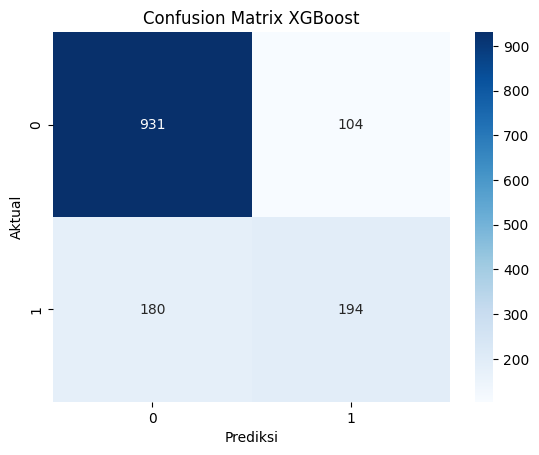

In [ ]:
print("Accuracy :", accuracy_score(y_test, xgb_pred))
print("Precision:", precision_score(y_test, xgb_pred, zero_division=0))
print("Recall   :", recall_score(y_test, xgb_pred, zero_division=0))
print("F1-score :", f1_score(y_test, xgb_pred, zero_division=0))
print("ROC-AUC  :", roc_auc_score(y_test, xgb_prob))

print("\nClassification report:")
print(classification_report(
    y_test,
    xgb_pred,
    target_names=["No Churn", "Churn"],
    zero_division=0
))

cm = confusion_matrix(y_test, xgb_pred)

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Prediksi")
plt.ylabel("Aktual")
plt.title("Confusion Matrix XGBoost")
plt.show()

In [ ]:
# Membuat tabel hasil prediksi XGBoost
hasil_xgb = pd.DataFrame({
    "customerID": test_df["customerID"].values,
    "Churn_Aktual": y_test.values,
    "Probabilitas_Churn": xgb_prob,
    "Prediksi_Churn": xgb_pred
})

# Mengubah label angka menjadi teks
hasil_xgb["Churn_Aktual"] = hasil_xgb["Churn_Aktual"].map({
    0: "No Churn",
    1: "Churn"
})

hasil_xgb["Prediksi_Churn"] = hasil_xgb["Prediksi_Churn"].map({
    0: "No Churn",
    1: "Churn"
})

# Menambahkan status benar atau salah
hasil_xgb["Hasil_Prediksi"] = np.where(
    hasil_xgb["Churn_Aktual"] == hasil_xgb["Prediksi_Churn"],
    "Benar",
    "Salah"
)

# Menampilkan hasil
display(hasil_xgb.head(20))

,customerID,Churn_Aktual,Probabilitas_Churn,Prediksi_Churn,Hasil_Prediksi
0,4376-KFVRS,No Churn,0.010975,No Churn,Benar
1,2754-SDJRD,No Churn,0.878565,Churn,Salah
2,9917-KWRBE,No Churn,0.084913,No Churn,Benar
3,0365-GXEZS,No Churn,0.371715,No Churn,Benar
4,9385-NXKDA,No Churn,0.006484,No Churn,Benar
5,4686-UXDML,No Churn,0.660369,Churn,Salah
6,2227-JRSJX,No Churn,0.465671,No Churn,Benar
7,4830-FAXFM,No Churn,0.110836,No Churn,Benar
8,1830-IPXVJ,No Churn,0.018562,No Churn,Benar
9,4690-LLKUA,Churn,0.415819,No Churn,Salah


#RSF

In [ ]:
# Event = True apabila churn
event_train = (train_df["Churn"] == "Yes").to_numpy()
event_test = (test_df["Churn"] == "Yes").to_numpy()

# Waktu dalam bulan
time_train = train_df["tenure"].to_numpy(dtype=float)
time_test = test_df["tenure"].to_numpy(dtype=float)

# Bentuk target survival
y_train_surv = Surv.from_arrays(
    event=event_train,
    time=time_train
)

y_test_surv = Surv.from_arrays(
    event=event_test,
    time=time_test
)

rsf_model = RandomSurvivalForest(
    n_estimators=300,
    min_samples_split=10,
    min_samples_leaf=10,
    max_features="sqrt",
    random_state=42,
    n_jobs=-1
)

rsf_model.fit(X_train_rsf, y_train_surv)

RandomSurvivalForest(min_samples_leaf=10, min_samples_split=10,
                     n_estimators=300, n_jobs=-1, random_state=42)

In [ ]:
# Risk Score
rsf_risk = rsf_model.predict(X_test_rsf)

In [ ]:
import numpy as np
import pandas as pd

from sksurv.metrics import (
    concordance_index_censored,
    concordance_index_ipcw,
    integrated_brier_score,
    brier_score,
    cumulative_dynamic_auc
)

In [ ]:
# Prediksi risiko relatif
rsf_risk = rsf_model.predict(X_test_rsf)

# C-index standar
c_index = concordance_index_censored(
    y_test_surv["event"],
    y_test_surv["time"],
    rsf_risk
)[0]

print("C-index      :", round(c_index, 4))

C-index      : 0.8404


In [ ]:
train_time = y_train_surv["time"]
test_time = y_test_surv["time"]

candidate_times = np.array([12, 24, 36], dtype=float)

# Pilih horizon yang berada dalam rentang waktu train dan test
lower_bound = max(train_time.min(), test_time.min())
upper_bound = min(train_time.max(), test_time.max())

times = candidate_times[
    (candidate_times > lower_bound) &
    (candidate_times < upper_bound)
]

print("Rentang waktu train:", train_time.min(), "-", train_time.max())
print("Rentang waktu test :", test_time.min(), "-", test_time.max())
print("Horizon evaluasi yang dipakai:", times)

Rentang waktu train: 0.0 - 72.0
Rentang waktu test : 0.0 - 72.0
Horizon evaluasi yang dipakai: [12. 24. 36.]


In [ ]:
if len(times) >= 2:
    # Prediksi probabilitas survival pada setiap horizon
    survival_functions = rsf_model.predict_survival_function(
        X_test_rsf
    )

    survival_prob = np.row_stack([
        fn(times) for fn in survival_functions
    ])

    # Brier Score untuk setiap horizon
    eval_times, brier_scores = brier_score(
        y_train_surv,
        y_test_surv,
        survival_prob,
        times
    )

    print("BRIER SCORE")
    for t, score in zip(eval_times, brier_scores):
        print(f"Brier Score pada {t:.0f} bulan: {score:.4f}")

    # Integrated Brier Score
    ibs = integrated_brier_score(
        y_train_surv,
        y_test_surv,
        survival_prob,
        times
    )

    print("\nIntegrated Brier Score (IBS):", round(ibs, 4))

else:
    print(
        "Horizon belum cukup untuk menghitung IBS. "
    )

BRIER SCORE
Brier Score pada 12 bulan: 0.0936
Brier Score pada 24 bulan: 0.0982
Brier Score pada 36 bulan: 0.0985

Integrated Brier Score (IBS): 0.0971


/tmp/ipykernel_26225/2153148780.py:7: DeprecationWarning: `row_stack` alias is deprecated. Use `np.vstack` directly.
  survival_prob = np.row_stack([


In [ ]:
print("Distribusi status event pada data train:")
print(pd.Series(y_train_surv["event"]).value_counts())

print("\nRentang waktu train:")
print("Minimum:", y_train_surv["time"].min())
print("Maksimum:", y_train_surv["time"].max())

print("\nRentang waktu test:")
print("Minimum:", y_test_surv["time"].min())
print("Maksimum:", y_test_surv["time"].max())

print("\nJumlah event churn pada data test:")
print(y_test_surv["event"].sum())

Distribusi status event pada data train:
False    4139
True     1495
Name: count, dtype: int64

Rentang waktu train:
Minimum: 0.0
Maksimum: 72.0

Rentang waktu test:
Minimum: 0.0
Maksimum: 72.0

Jumlah event churn pada data test:
374


In [ ]:
# Membuat tabel hasil prediksi RSF
hasil_rsf = pd.DataFrame({
    "customerID": test_df["customerID"].values,
    "Waktu_Tercatat_Bulan": y_test_surv["time"],
    "Event_Churn": y_test_surv["event"],
    "RSF_Risk_Score": rsf_risk
})

# Mengubah event menjadi label
hasil_rsf["Event_Churn"] = hasil_rsf["Event_Churn"].map({
    False: "Tidak Churn (Tersensor)",
    True: "Churn"
})

# Mengurutkan pelanggan dari skor risiko tertinggi
hasil_rsf = hasil_rsf.sort_values(
    by="RSF_Risk_Score",
    ascending=False
).reset_index(drop=True)

# Menampilkan 20 pelanggan dengan skor risiko tertinggi
display(hasil_rsf.head(20))

,customerID,Waktu_Tercatat_Bulan,Event_Churn,RSF_Risk_Score
0,8752-STIVR,4.0,Churn,140.935819
1,8375-DKEBR,1.0,Churn,126.971296
2,4342-HENTK,2.0,Churn,124.755311
3,2514-GINMM,1.0,Churn,121.059655
4,1016-DJTSV,8.0,Tidak Churn (Tersensor),117.155187
5,5376-DEQCP,1.0,Churn,116.617131
6,7130-VTEWQ,8.0,Churn,116.464826
7,6077-BDPXA,3.0,Tidak Churn (Tersensor),116.142355
8,0685-MLYYM,2.0,Churn,115.803739
9,9112-WSNPU,35.0,Tidak Churn (Tersensor),115.729873


# Segmentasi K-means

In [ ]:

# Ambil hanya kolom yang dibutuhkan untuk integrasi
data_xgb = hasil_xgb[
    ["customerID", "Probabilitas_Churn", "Churn_Aktual"]
].copy()

data_rsf = hasil_rsf[
    ["customerID", "RSF_Risk_Score"]
].copy()

# Integrasikan berdasarkan customerID
data_integrasi = pd.merge(
    data_xgb,
    data_rsf,
    on="customerID",
    how="inner",
    validate="one_to_one"
)

# Periksa hasil integrasi
print("Jumlah baris hasil integrasi:", len(data_integrasi))
print("Jumlah customer unik:", data_integrasi["customerID"].nunique())
print("\nLima data pertama:")

display(data_integrasi.head(10))

Jumlah baris hasil integrasi: 1409
Jumlah customer unik: 1409

Lima data pertama:


,customerID,Probabilitas_Churn,Churn_Aktual,RSF_Risk_Score
0,4376-KFVRS,0.010975,No Churn,0.171654
1,2754-SDJRD,0.878565,No Churn,47.691825
2,9917-KWRBE,0.084913,No Churn,2.704478
3,0365-GXEZS,0.371715,No Churn,40.873754
4,9385-NXKDA,0.006484,No Churn,0.556004
5,4686-UXDML,0.660369,No Churn,49.995413
6,2227-JRSJX,0.465671,No Churn,33.354605
7,4830-FAXFM,0.110836,No Churn,14.912797
8,1830-IPXVJ,0.018562,No Churn,0.249840
9,4690-LLKUA,0.415819,Churn,109.691216


In [ ]:
from sklearn.preprocessing import StandardScaler

# Fitur yang digunakan untuk segmentasi
fitur_cluster = [
    "Probabilitas_Churn",
    "RSF_Risk_Score"
]

X_cluster = data_integrasi[fitur_cluster].copy()

# Pastikan tidak ada nilai kosong atau tak hingga
if not np.isfinite(X_cluster.to_numpy()).all():
    raise ValueError(
        "Fitur clustering mengandung nilai kosong atau tak hingga. "
        "Periksa hasil integrasi terlebih dahulu."
    )

# Standardisasi
scaler = StandardScaler()
X_cluster_scaled = scaler.fit_transform(X_cluster)

print("Dimensi fitur:", X_cluster_scaled.shape)
print("Rata-rata fitur setelah standardisasi:",
      X_cluster_scaled.mean(axis=0))
print("Standar deviasi fitur setelah standardisasi:",
      X_cluster_scaled.std(axis=0))

Dimensi fitur: (1409, 2)
Rata-rata fitur setelah standardisasi: [ 6.42968054e-17 -1.08422064e-16]
Standar deviasi fitur setelah standardisasi: [1. 1.]


In [ ]:
from sklearn.cluster import KMeans

# Membentuk 3 cluster
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=20
)

data_integrasi["Cluster"] = kmeans.fit_predict(
    X_cluster_scaled
)

print("Jumlah pelanggan per cluster:")
display(
    data_integrasi["Cluster"]
    .value_counts()
    .sort_index()
    .rename("Jumlah_Pelanggan")
    .to_frame()
)

Jumlah pelanggan per cluster:


,Jumlah_Pelanggan
Cluster,
0,805
1,263
2,341


In [ ]:
# Ringkasan skor per cluster
profil_cluster = (
    data_integrasi
    .groupby("Cluster")
    .agg(
        Jumlah_Pelanggan=("customerID", "nunique"),
        Rata_Probabilitas_Churn=("Probabilitas_Churn", "mean"),
        Rata_RSF_Risk=("RSF_Risk_Score", "mean"),
        Proporsi_Churn_Aktual=(
            "Churn_Aktual",
            lambda x: (x == "Churn").mean()
        )
    )
)

# Standardisasi skor rata-rata agar dapat dibandingkan
# untuk tujuan pengurutan cluster
mean_xgb_z = (
    profil_cluster["Rata_Probabilitas_Churn"]
    - profil_cluster["Rata_Probabilitas_Churn"].mean()
) / profil_cluster["Rata_Probabilitas_Churn"].std()

mean_rsf_z = (
    profil_cluster["Rata_RSF_Risk"]
    - profil_cluster["Rata_RSF_Risk"].mean()
) / profil_cluster["Rata_RSF_Risk"].std()

profil_cluster["Skor_Risiko_Rata_Rata"] = (
    mean_xgb_z + mean_rsf_z
) / 2

# Urutkan cluster dari risiko terendah ke tertinggi
urutan_risiko = profil_cluster[
    "Skor_Risiko_Rata_Rata"
].sort_values().index.tolist()

nama_risiko = {
    urutan_risiko[0]: "Low Risk",
    urutan_risiko[1]: "Medium Risk",
    urutan_risiko[2]: "High Risk",
}

data_integrasi["Segmen_Risiko"] = (
    data_integrasi["Cluster"].map(nama_risiko)
)

profil_cluster["Segmen_Risiko"] = (
    profil_cluster.index.map(nama_risiko)
)

print("Profil setiap segmen:")
display(
    profil_cluster.sort_values("Skor_Risiko_Rata_Rata")
)

Profil setiap segmen:


,Jumlah_Pelanggan,Rata_Probabilitas_Churn,Rata_RSF_Risk,Proporsi_Churn_Aktual,Skor_Risiko_Rata_Rata,Segmen_Risiko
Cluster,,,,,,
0,805,0.072858,8.489974,0.090683,-0.993366,Low Risk
2,341,0.404272,41.976012,0.375367,-0.007765,Medium Risk
1,263,0.666532,86.361950,0.657795,1.001131,High Risk


In [ ]:
#Evaluasi
from sklearn.metrics import silhouette_score

sil_score = silhouette_score(
    X_cluster_scaled,
    data_integrasi["Cluster"]
)

print(f"Silhouette Score: {sil_score:.4f}")

Silhouette Score: 0.5653


In [ ]:
# Urutan tampilan segmen
urutan_segmen = ["Low Risk", "Medium Risk", "High Risk"]

for segmen in urutan_segmen:
    data_segmen = hasil_segmentasi[
        hasil_segmentasi["Segmen_Risiko"] == segmen
    ].copy()

    print(f"\n{'_'*60}")
    print(f"\nSEGMEN: {segmen}")
    print(f"Jumlah pelanggan: {len(data_segmen)}")
    print(f"{'_'*60}")

    display(data_segmen)


____________________________________________________________

SEGMEN: Low Risk
Jumlah pelanggan: 805
____________________________________________________________


,customerID,Probabilitas_Churn,RSF_Risk_Score,Cluster,Segmen_Risiko,Churn_Aktual
0,4376-KFVRS,0.010975,0.171654,0,Low Risk,No Churn
2,9917-KWRBE,0.084913,2.704478,0,Low Risk,No Churn
4,9385-NXKDA,0.006484,0.556004,0,Low Risk,No Churn
7,4830-FAXFM,0.110836,14.912797,0,Low Risk,No Churn
8,1830-IPXVJ,0.018562,0.249840,0,Low Risk,No Churn
...,...,...,...,...,...,...
1404,5204-HMGYF,0.034894,5.872412,0,Low Risk,No Churn
1405,9950-MTGYX,0.004384,0.317480,0,Low Risk,No Churn
1406,3675-EQOZA,0.109654,21.593373,0,Low Risk,No Churn
1407,3646-ITDGM,0.053898,1.182632,0,Low Risk,No Churn



____________________________________________________________

SEGMEN: Medium Risk
Jumlah pelanggan: 341
____________________________________________________________


,customerID,Probabilitas_Churn,RSF_Risk_Score,Cluster,Segmen_Risiko,Churn_Aktual
3,0365-GXEZS,0.371715,40.873754,2,Medium Risk,No Churn
5,4686-UXDML,0.660369,49.995413,2,Medium Risk,No Churn
6,2227-JRSJX,0.465671,33.354605,2,Medium Risk,No Churn
10,5804-HYIEZ,0.352709,14.343806,2,Medium Risk,No Churn
12,5533-RJFTJ,0.228319,50.198060,2,Medium Risk,No Churn
...,...,...,...,...,...,...
1378,0778-NELLA,0.436272,43.495657,2,Medium Risk,Churn
1379,7495-OOKFY,0.746262,35.735450,2,Medium Risk,Churn
1386,3524-WQDSG,0.636299,41.379375,2,Medium Risk,No Churn
1390,5331-RGMTT,0.612907,39.709757,2,Medium Risk,No Churn



____________________________________________________________

SEGMEN: High Risk
Jumlah pelanggan: 263
____________________________________________________________


,customerID,Probabilitas_Churn,RSF_Risk_Score,Cluster,Segmen_Risiko,Churn_Aktual
1,2754-SDJRD,0.878565,47.691825,1,High Risk,No Churn
9,4690-LLKUA,0.415819,109.691216,1,High Risk,Churn
13,4706-AXVKM,0.763458,65.119777,1,High Risk,Churn
17,1379-FRVEB,0.632073,63.042662,1,High Risk,No Churn
20,7235-NXZCP,0.699552,76.308256,1,High Risk,Churn
...,...,...,...,...,...,...
1388,8601-QACRS,0.497495,75.625110,1,High Risk,Churn
1393,0679-IDSTG,0.908776,92.676363,1,High Risk,Churn
1395,2101-RANCD,0.335647,102.633184,1,High Risk,No Churn
1396,4029-HPFVY,0.553625,78.185610,1,High Risk,No Churn


In [ ]:
profil_detail = (
    hasil_segmentasi
    .groupby(["Cluster", "Segmen_Risiko"])
    .agg(
        Jumlah_Pelanggan=("customerID", "nunique"),
        Rata_Rata_Probabilitas_Churn=("Probabilitas_Churn", "mean"),
        Min_Probabilitas_Churn=("Probabilitas_Churn", "min"),
        Max_Probabilitas_Churn=("Probabilitas_Churn", "max"),
        Rata_Rata_RSF_Risk=("RSF_Risk_Score", "mean"),
        Churn_Aktual=("Churn_Aktual",
                      lambda x: (x == "Churn").sum()),
        Non_Churn_Aktual=("Churn_Aktual",
                          lambda x: (x == "No Churn").sum())
    )
    .reset_index()
)

profil_detail["Persentase_Churn_Aktual"] = (
    profil_detail["Churn_Aktual"]
    / profil_detail["Jumlah_Pelanggan"] * 100
).round(2)

display(profil_detail.round(4))

,Cluster,Segmen_Risiko,Jumlah_Pelanggan,Rata_Rata_Probabilitas_Churn,Min_Probabilitas_Churn,Max_Probabilitas_Churn,Rata_Rata_RSF_Risk,Churn_Aktual,Non_Churn_Aktual,Persentase_Churn_Aktual
0,0,Low Risk,805,0.0729,0.0017,0.3340,8.490,73,732,9.07
1,1,High Risk,263,0.6665,0.2348,0.9475,86.362,173,90,65.78
2,2,Medium Risk,341,0.4043,0.0854,0.8632,41.976,128,213,37.54
